![Banner](../images/09_07_banner_rs_texture.png)


# Texture Analysis of Landsat Imagery: Statistical and Structural Methods

Statistical texture methods describe how gray levels are distributed inside a window, either one pixel at a time (first-order statistics), in pairs of pixels (the Gray-Level Co-occurrence Matrix, GLCM), or along runs of equal pixels (the Gray-Level Run-Length Matrix, GLRLM).


## Overview

Structural methods treat texture as primitives, such as edges and gaps, arranged in space. Together they are the most widely used texture measures in remote sensing. This notebook explains the theory of each method, computes it on the NIR band of a Landsat 9 scene over Las Vegas with `geolattice.rsense.texture`, and tests what it adds to spectral information.


### Image texture in brief

Spectral values tell us *what* a pixel is made of; **texture** tells us *how pixel values are arranged*
around it. Texture is the spatial variation of gray levels inside a neighbourhood and describes
properties such as smoothness, coarseness, regularity, directionality and contrast. Haralick,
Shanmugam and Dinstein (1973) noted that tone and texture are always present together in an image, but
one may dominate the other depending on the scene.

At Landsat's 30 m resolution many land-cover classes overlap spectrally: urban fabric, bare soil and
rock are all bright and dry in an arid scene; crop types or forest stands can share the same NDVI;
rough terrain mixes lit slopes and shadow within a few pixels. Texture separates such classes because
it responds to *pattern*, not only to *brightness*, and texture layers are routinely stacked with bands
and indices as predictors in land-cover classification, urban mapping, forest-structure modelling and
soil mapping.

Methods are usually grouped into six families. This series covers them in five notebooks:

| Notebook | Family | Methods |
|---|---|---|
| 09_07_01 | **Statistical and structural texture** (this notebook) | First-order statistics, GLCM, GLRLM, edge density, lacunarity |
| 09_07_02 | [Transform-based (spectral) texture](09_07_02_texture_analysis_of_landsat_imagery_transform_based_spectral_methods.ipynb) | Fourier power spectrum, Gabor filter bank, Haar wavelets |
| 09_07_03 | [Local pattern-based texture](09_07_03_texture_analysis_of_landsat_imagery_local_pattern_based_methods_lbp.ipynb) | Local Binary Patterns (LBP) |
| 09_07_04 | [Model-based texture](09_07_04_texture_analysis_of_landsat_imagery_model_based_methods.ipynb) | Markov Random Field energy, fractal dimension, autoregressive model |
| 09_07_05 | [Deep-learning-based texture](09_07_05_texture_analysis_of_landsat_imagery_deep_learning_based_methods.ipynb) | Pretrained CNN feature maps |

All methods come from `geolattice.rsense.texture`. Every function accepts a 2-D `xr.DataArray` (or NumPy
array) and returns a georeferenced result with the same shape as the input; inputs with leading
dimensions (band, time, polarization) are processed slice by slice, and multi-feature methods return an
`xr.Dataset` with one variable per feature.


### Statistical methods: theory

Let $g(x, y)$ be the gray level (reflectance) of the pixel at row $y$, column $x$, and let $W$ be a
square window of $N = s \times s$ pixels centred on a pixel. Statistical texture summarizes the values
in $W$ at three levels of order.

**First-order statistics** use only the histogram of $W$ and ignore where the values are:

| Measure | Formula | Describes |
|---|---|---|
| Mean | $\mu = \frac{1}{N}\sum_{W} g$ | Local brightness (a smoothed image) |
| Variance / std | $\sigma^2 = \frac{1}{N}\sum_{W}(g-\mu)^2$ | Local contrast or roughness |
| Skewness | $\frac{1}{N\sigma^3}\sum_{W}(g-\mu)^3$ | Asymmetry: a few bright objects on a dark background (> 0) or the reverse (< 0) |
| Excess kurtosis | $\frac{1}{N\sigma^4}\sum_{W}(g-\mu)^4 - 3$ | Heavy tails: isolated extreme pixels |
| Entropy | $-\sum_k p_k \log_2 p_k$ | Disorder of the local histogram ($p_k$ = share of pixels in bin $k$) |

**Second-order statistics (GLCM).** Haralick et al. (1973) proposed counting how often gray level $i$
occurs at a fixed offset from gray level $j$. For a displacement of $d$ pixels at angle $\theta$, the
co-occurrence matrix of a window quantized to $L$ levels is

$$C_{d,\theta}(i, j) = \#\{\,(p, q) \in W : g(p) = i,\; g(q) = j,\; q = p + d(\cos\theta, -\sin\theta)\,\}.$$

The matrix is made symmetric ($C + C^\top$, counting each pair in both directions) and normalized to
probabilities $P(i, j) = C(i, j) / \sum C$. With $\mu_i = \sum i\,P(i,j)$ and
$\sigma_i^2 = \sum (i-\mu_i)^2 P(i,j)$, the classic Haralick features are:

| Feature | Formula | High for |
|---|---|---|
| Contrast | $\sum_{i,j} P(i,j)\,(i-j)^2$ | Strong local variation (city blocks, edges) |
| Dissimilarity | $\sum_{i,j} P(i,j)\,\lvert i-j\rvert$ | Same as contrast, but linear in the difference |
| Homogeneity (IDM) | $\sum_{i,j} P(i,j) / (1+(i-j)^2)$ | Neighbours with similar values (smooth soil, water) |
| Energy (ASM$^{1/2}$) | $\sqrt{\sum_{i,j} P(i,j)^2}$ | A few dominant gray-level pairs (uniform, orderly texture) |
| Correlation | $\sum_{i,j} P(i,j)\,(i-\mu_i)(j-\mu_j) / (\sigma_i\sigma_j)$ | Linear, gradual change between neighbours |
| Entropy | $-\sum_{i,j} P(i,j)\log_2 P(i,j)$ | Many different gray-level pairs (disorder) |

**Higher-order statistics (GLRLM).** Galloway (1975) counted *runs*: maximal sequences of consecutive
pixels with the same quantized gray level along a direction. The run-length matrix $R(i, r)$ is the
number of runs of gray level $i$ and length $r$. With $n_r$ the total number of runs and $N_p$ the
number of pixels (times the number of directions),

$$\mathrm{SRE} = \frac{1}{n_r}\sum_{i,r}\frac{R(i,r)}{r^2},\qquad
\mathrm{LRE} = \frac{1}{n_r}\sum_{i,r} R(i,r)\,r^2,\qquad
\mathrm{RP} = \frac{n_r}{N_p}.$$

Short runs (high SRE, high RP) mean fine texture; long runs (high LRE, low RP) mean coarse or striped
texture.


### Structural methods: theory

Structural (syntactic) texture analysis treats an image as **primitives** placed by **rules**: bricks in
a wall, buildings along a street, ridges in a fold belt. Full syntactic grammars are rarely practical on
satellite imagery, so two simple density measures are used instead.

**Edge density.** The Canny (1986) detector finds edge primitives in four steps: Gaussian smoothing
(scale $\sigma$), gradient magnitude and direction, non-maximum suppression (thin edges to one pixel),
and hysteresis thresholding (keep strong edges and the weak edges connected to them). Edge density is
the share of edge pixels in each window,
$\;\mathrm{ED} = \frac{1}{N}\sum_W \mathbb{1}[\text{edge}]$.

**Lacunarity.** Plotnick et al. (1996) measure how unevenly "mass" fills space. A box of side $r$ glides
over the image; the mass $M$ in each box is the sum of the values inside it. Lacunarity at scale $r$ is

$$\Lambda(r) = \frac{\operatorname{Var}(M)}{\operatorname{E}(M)^2} + 1.$$

$\Lambda(r) = 1$ for a perfectly uniform pattern; larger values mean gaps and clumps at that scale.
Plotting $\Lambda$ against $r$ shows the scales at which a pattern is heterogeneous.


### Applications

| Application | Typical measures | Why it works |
|---|---|---|
| Urban and impervious-surface mapping | GLCM contrast, entropy, local std, edge density | Built-up areas alternate roofs, roads and vegetation at a fine scale |
| Forest structure and biomass | GLCM homogeneity, entropy, local variance | Canopy gaps and crown size change the local variance |
| Crop-type and field mapping | GLCM, GLRLM, directional GLCM | Row direction and field size create runs and directional contrast |
| SAR land-cover classification | GLCM on backscatter, first-order statistics | Speckle statistics differ between smooth water, fields and forest |
| Geology and landforms | Directional GLCM, edge density | Bedding, faults and drainage have a preferred direction |
| Soil and digital soil mapping | Local std, GLCM homogeneity of bare-soil bands | Erosion, stones and crusts change surface roughness |
| Landscape ecology | Lacunarity | Gap structure of habitat patches across scales |


### Learning objectives

1. Explain first-order, co-occurrence (GLCM) and run-length (GLRLM) statistics and compute them by hand
   on a small example.
2. Explain the edge-density and lacunarity measures of structural texture.
3. Compute all five methods on Landsat NIR with `geolattice.rsense.texture` and interpret each feature.
4. Assess the effect of window size, gray levels, direction and band on texture values.
5. Compare texture signatures of urban, bare-soil and mountain surfaces and test what statistical
   texture adds to an unsupervised classification.


### Data

| File | Content |
|---|---|
| `data/blue.tif` | Landsat 9 OLI-2 band 2 (blue), Collection 2 Level-2 surface reflectance DN |
| `data/green.tif` | Landsat 9 OLI-2 band 3 (green) |
| `data/red.tif` | Landsat 9 OLI-2 band 4 (red) |
| `data/nir.tif` | Landsat 9 OLI-2 band 5 (NIR) |

All four bands come from the Las Vegas scene used in the Landsat module
([09_02_04_landsat_half_a_century_of_earth_observation](../09_02_optical/09_02_04_landsat_half_a_century_of_earth_observation.ipynb)): path 39, row 35, 8 July 2024, UTM zone
11N (EPSG:32611), 30 m, 1,679 × 1,512 pixels, stored as unsigned 16-bit DN with 0 as the fill value.


### Contents

1. Setup
2. Loading the Landsat bands and the study window
3. Why texture? Same histogram, different arrangement
4. First-order statistics
5. Gray-Level Co-occurrence Matrix (GLCM)
6. Gray-Level Run-Length Matrix (GLRLM)
7. Structural texture: edge density and lacunarity
8. Application: texture signatures and clustering
9. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup: silence noisy warnings, import the libraries and choose the array backend.
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # e.g. 'mean of empty slice' in all-NaN windows
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecation notices from pandas and xarray

import time  # time each texture computation
from pathlib import Path  # portable file paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters (DataArray, Dataset)
import rasterio  # GeoTIFF reading and writing
import matplotlib.pyplot as plt  # figures
from matplotlib.patches import Rectangle  # draw the study-window rectangle

import geolattice.rsense as rs  # GeoLattice remote sensing: reading, scaling and plotting
from geolattice.rsense import texture as tx  # GeoLattice texture functions

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages for the whole session
plt.rcParams.update({"figure.dpi": 90})  # figure resolution
# "cpu" keeps every array on NumPy; the texture functions copy GPU arrays to the CPU anyway.
# report the GeoLattice version and switch to the NumPy (CPU) backend
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))

geolattice.rsense 0.3.49 | backend: cpu


## Loading the Landsat bands and the study window

The files hold raw Collection 2 Level-2 digital numbers (DN). We read them with `rs.read`, put them in
one `xr.Dataset`, and convert them to surface reflectance with `rs.optical.scale`, which applies
**reflectance = DN × 0.0000275 − 0.2** and turns the fill value 0 into NaN.

Window-based texture is easier to see, and much faster to compute, on a smaller area. We work on a
512 × 512 pixel window (15.4 × 15.4 km) on the eastern edge of Las Vegas that contains four very
different surfaces:

- the regular **street grid** of the city (west),
- the smooth, bare **alluvial fan** below Frenchman Mountain (centre),
- the folded sedimentary **ridges of Frenchman Mountain** (east),
- the vegetated channel of the **Las Vegas Wash** (south), red in colour infrared.


In [2]:
# 1. Read each band as a 2-D DataArray (drop the singleton "band" dimension).
DATA = Path("../../../../Data/00_shared/data_remote_sensing/landsat9_vegas_20240708/LC09_L2SP_039035_20240708_02_T1")  # Landsat 9 scene, path 39 row 35, 8 July 2024
BANDS = ["blue", "green", "red", "nir"]  # the four bands used in this notebook
# read each band; masked=False keeps the raw digital numbers (DN)
ls_dn = xr.Dataset({b: rs.read(DATA / f"{b}.tif", masked=False).squeeze("band", drop=True)
                    for b in BANDS})  # one variable per band
ls_dn = ls_dn.rio.write_crs(ls_dn["red"].rio.crs)  # store the CRS on the Dataset as a whole

# 2. Scale DN to surface reflectance (fill value 0 becomes NaN) and clip to [1e-4, 1].
# Landsat Collection 2 scale and offset: DN -> reflectance
ls = rs.optical.scale(ls_dn, sensor="landsat").clip(min=1e-4, max=1.0)
# scene size, pixel size and CRS
print(f"{ls.rio.width} x {ls.rio.height} pixels at {ls.rio.resolution()[0]:.0f} m, CRS {ls.rio.crs}")

# 3. Study window (rows/columns in the full scene) and the NIR band used for most texture measures.
WIN = dict(y=slice(500, 1012), x=slice(900, 1412))  # 512 x 512 pixel window (rows 500-1011, columns 900-1411)
sub = ls.isel(WIN)  # all four bands inside the window
nir = sub["nir"]  # the NIR band of the window

1679 x 1512 pixels at 30 m, CRS EPSG:32611


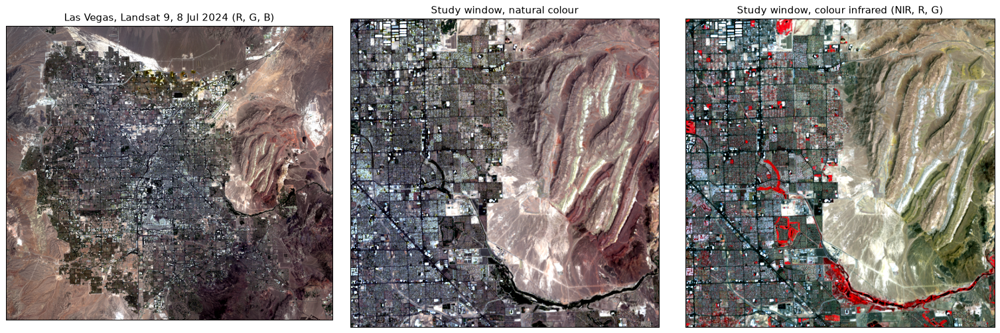

In [3]:
# Where the study window lies, and how it looks in natural colour and colour infrared.
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))  # three panels side by side
# full scene, red-green-blue
rs.viz.plot_rgb(ls, "true_color", ax=axes[0], title="Las Vegas, Landsat 9, 8 Jul 2024 (R, G, B)")
# the study window in yellow (x = column 900, y = row 500)
axes[0].add_patch(Rectangle((900, 500), 512, 512, fill=False, ec="yellow", lw=2))
# the window in natural colour
rs.viz.plot_rgb(sub, "true_color", ax=axes[1], title="Study window, natural colour")
# NIR, red, green: vegetation appears red
rs.viz.plot_rgb(sub, "false_color", ax=axes[2], title="Study window, colour infrared (NIR, R, G)")
for a in axes:  # hide the pixel ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

### Which band?

Texture is computed on one band at a time. The table shows how similar the four bands are inside the
window; strongly correlated bands give almost the same texture.


In [4]:
# Correlation between the four bands in the study window (one row per pixel).
band_df = sub.to_dataframe()[BANDS].dropna()  # pixels as rows, bands as columns; drop no-data pixels
band_df.corr().round(3)  # Pearson correlation matrix, shown as a table

,blue,green,red,nir
blue,1.000,0.972,0.906,0.731
green,0.972,1.000,0.956,0.802
red,0.906,0.956,1.000,0.846
nir,0.731,0.802,0.846,1.000


The three visible bands are almost interchangeable inside the window (r = 0.91 to 0.97), so their
textures will be nearly identical. NIR is less correlated with them (r = 0.73 to 0.85) and carries the
most distinct information. It is the texture band for the rest of this notebook.


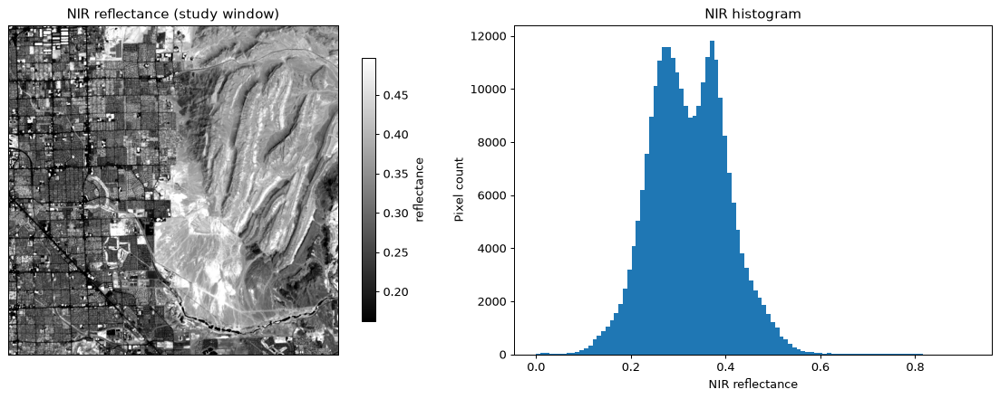

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))  # image on the left, histogram on the right
# the NIR window as a grey image
rs.viz.plot_raster(nir, ax=axes[0], cmap="gray", title="NIR reflectance (study window)")
axes[1].hist(nir.values.ravel(), bins=100, color="C0")  # distribution of all NIR values
axes[1].set(xlabel="NIR reflectance", ylabel="Pixel count", title="NIR histogram")  # axis labels and title
axes[0].set_xticks([]); axes[0].set_yticks([])  # no pixel ticks on the image
plt.tight_layout(); plt.show()  # arrange and draw

## Why texture? Same histogram, different arrangement

We take a 64 × 64 patch of the city grid and randomly shuffle its pixels. The shuffled patch has
**exactly the same histogram**, so every first-order statistic of the whole patch is identical; only
the spatial arrangement changed. A second-order measure such as GLCM contrast sees the difference.


In [6]:
# 1. A 64 x 64 patch of the street grid and a copy with its pixels randomly shuffled.
patch = nir.isel(y=slice(96, 160), x=slice(32, 96)).values  # rows 96-159, columns 32-95 of the window
rng = np.random.default_rng(0)  # random generator with a fixed seed
# the same values in random positions: same histogram, no spatial structure
shuffled = rng.permutation(patch.ravel()).reshape(patch.shape)

# 2. Whole-patch histogram statistics are identical by construction.
def patch_stats(a):  # mean, standard deviation and skewness of all values
    # skewness = third standardised moment
    return {"mean": a.mean(), "std": a.std(), "skewness": ((a - a.mean())**3).mean() / a.std()**3}

# 3. GLCM contrast and homogeneity of one 63 x 63 window at the patch centre.
def patch_glcm(a):  # GLCM features of one window covering the patch
    # step=64: a single 63 x 63 window at the centre
    g = tx.glcm_texture(a, size=63, step=64, props=("contrast", "homogeneity"))
    return {k: float(np.nanmean(v)) for k, v in g.items()}  # one number per feature

# compare original and shuffled side by side
pd.DataFrame({"original": {**patch_stats(patch), **patch_glcm(patch)},
              # the histogram statistics agree; the GLCM features do not
              "shuffled": {**patch_stats(shuffled), **patch_glcm(shuffled)}}).round(4)

,original,shuffled
mean,0.2829,0.2829
std,0.0728,0.0728
skewness,0.8405,0.8405
contrast,9.5407,26.7311
homogeneity,0.3819,0.2258


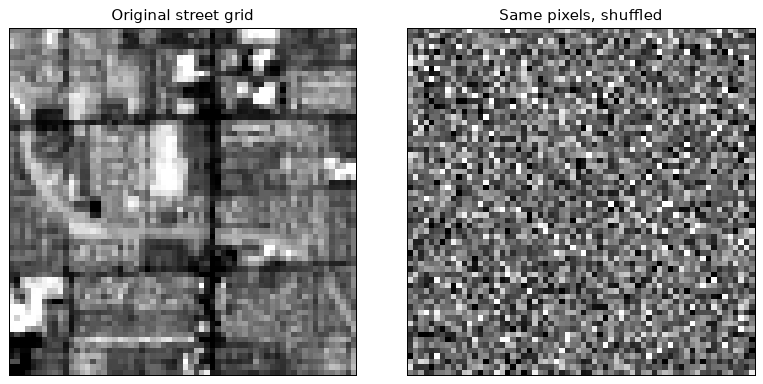

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.3))  # two panels
vmin, vmax = np.percentile(patch, [2, 98])  # a common 2-98 % stretch so both panels look comparable
# original and shuffled patch with their titles
for ax, a, t in zip(axes, [patch, shuffled], ["Original street grid", "Same pixels, shuffled"]):
    ax.imshow(a, cmap="gray", vmin=vmin, vmax=vmax); ax.set_title(t)  # show the patch in grey
    ax.set_xticks([]); ax.set_yticks([])  # no pixel ticks
plt.tight_layout(); plt.show()  # arrange and draw

Mean, standard deviation and skewness are identical, yet GLCM contrast almost triples (9.5 to 26.7) and
homogeneity falls from 0.38 to 0.23. In the real city, neighbouring pixels are similar (a roof next to a
roof, a road next to a road); in the shuffled patch every neighbour is a random draw. **Texture measures
the spatial dependence between pixels**, and first-order statistics cannot see it.


## First-order statistics

`tx.first_order_stats(img, size, stats, entropy_bins)` computes the moments of the previous section in a
moving `size` × `size` window, using box filters so it is fast even on a full scene. Entropy is the
Shannon entropy (bits) of a local histogram with `entropy_bins` levels (computed with a disk of radius
`size // 2`). NaN pixels stay NaN.

**Strengths:** fast, simple, easy to interpret, available in every GIS. **Limits:** blind to spatial
arrangement (see *Why texture? Same histogram, different arrangement*), so a speckled and a striped window with the same histogram look identical.


first_order_stats: 0.2 s -> ['mean', 'std', 'skewness', 'kurtosis', 'entropy']


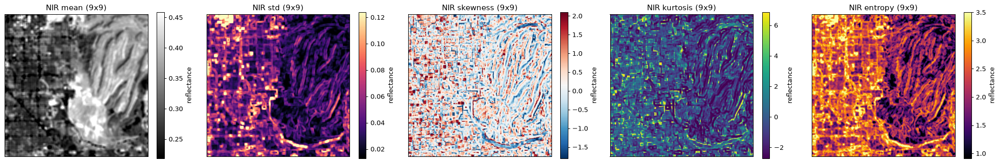

In [8]:
# First-order statistics of NIR in a 9 x 9 window (270 m).
t0 = time.time()  # start the timer
fos = tx.first_order_stats(nir, size=9)  # mean, std, skewness, kurtosis and entropy in each 9 x 9 window
# run time and the layers that were computed
print(f"first_order_stats: {time.time() - t0:.1f} s ->", list(fos.data_vars))

# a colour map per statistic
cm = {"mean": "gray", "std": "magma", "skewness": "RdBu_r", "kurtosis": "viridis", "entropy": "inferno"}
fig, axes = plt.subplots(1, 5, figsize=(22, 4.3))  # five panels
for ax, f in zip(axes, fos.data_vars):  # one panel per statistic
    rs.viz.plot_raster(fos[f], ax=ax, cmap=cm[f], title=f"NIR {f} (9x9)")  # draw the layer
    ax.set_xticks([]); ax.set_yticks([])  # no pixel ticks
plt.tight_layout(); plt.show()  # arrange and draw

`mean` is only a smoothed copy of the band: the bare fan is brightest, the city darkest. The other four
layers describe texture. Local `std` and `entropy` are high over the street grid, around the bright
commercial roofs in the north-west and along the vegetated Las Vegas Wash, and low on the fan and inside
the ridges. `skewness` and `kurtosis` are noisier; they pick out single bright or dark objects (a roof,
a pond) inside an otherwise uniform window.


### Window size

The window sets the spatial scale of the texture. A small window resolves individual objects but gives
noisy estimates (few pixels); a large window gives stable estimates but blurs class boundaries.


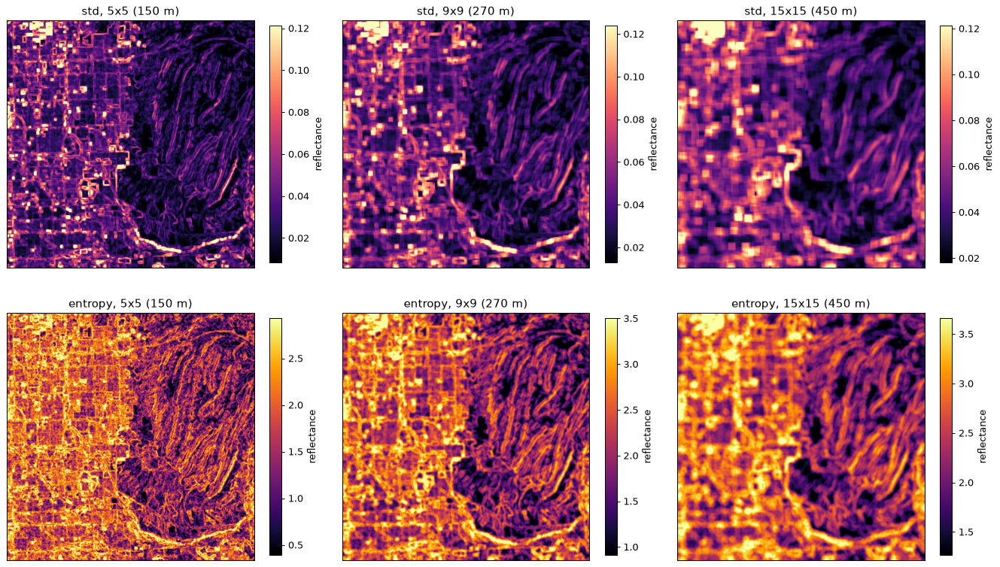

In [9]:
sizes = [5, 9, 15]  # window sizes in pixels (150, 270 and 450 m)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))  # rows: std and entropy; columns: window size
for j, s in enumerate(sizes):  # loop over window sizes
    f = tx.first_order_stats(nir, size=s, stats=("std", "entropy"))  # only the two statistics shown
    # local standard deviation
    rs.viz.plot_raster(f["std"], ax=axes[0, j], cmap="magma", title=f"std, {s}x{s} ({s*30} m)")
    # local entropy of the histogram
    rs.viz.plot_raster(f["entropy"], ax=axes[1, j], cmap="inferno", title=f"entropy, {s}x{s} ({s*30} m)")
for a in axes.ravel():  # no pixel ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

With a 5 × 5 window the maps resolve individual blocks and streets but are noisy. At 15 × 15 (450 m)
the city becomes one high-texture zone and the boundary between city and fan is smeared over several
hundred metres. A 9 × 9 window is a reasonable compromise for 30 m Landsat.


### First-order texture of the full scene


Full scene (1679 x 1512): 1.0 s


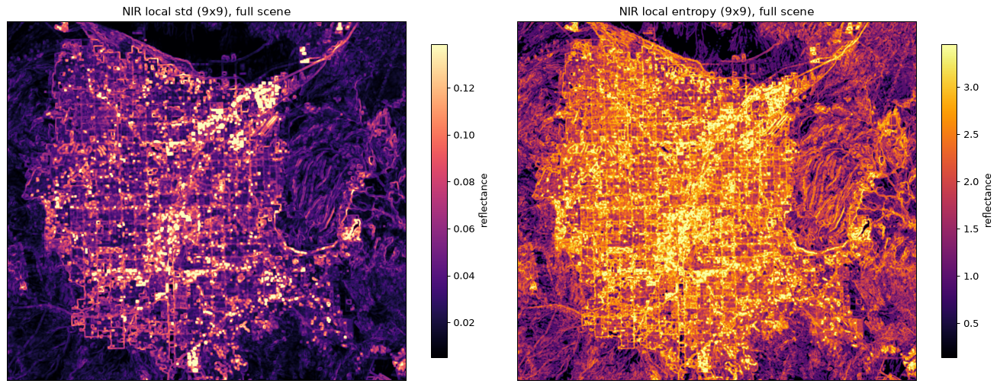

In [10]:
t0 = time.time()  # start the timer
# the same two statistics for the whole scene
fos_full = tx.first_order_stats(ls["nir"], size=9, stats=("std", "entropy"))
print(f"Full scene ({ls.rio.width} x {ls.rio.height}): {time.time() - t0:.1f} s")  # how long the full scene took

fig, axes = plt.subplots(1, 2, figsize=(15, 6))  # two panels
# local standard deviation
rs.viz.plot_raster(fos_full["std"], ax=axes[0], cmap="magma", title="NIR local std (9x9), full scene")
# local entropy
rs.viz.plot_raster(fos_full["entropy"], ax=axes[1], cmap="inferno", title="NIR local entropy (9x9), full scene")
for a in axes:  # for both panels:
    a.add_patch(Rectangle((900, 500), 512, 512, fill=False, ec="cyan", lw=1.5))  # mark the study window
    a.set_xticks([]); a.set_yticks([])  # no pixel ticks
plt.tight_layout(); plt.show()  # arrange and draw

At scene scale, texture outlines the urbanized valley: the city has high local std and entropy, the
surrounding desert basins low values. Mountain ranges sit in between, because ridges and gullies create
contrast only along their slopes.


## Gray-Level Co-occurrence Matrix (GLCM)

### A worked example

Before applying GLCM to Landsat, we build one by hand on the 4 × 4, 4-level test image used by
Haralick et al. (1973). For offset *d* = 1 at θ = 0° (the right-hand neighbour), we count every
(reference, neighbour) pair.


In [11]:
from skimage.feature import graycomatrix, graycoprops  # GLCM and its features from scikit-image

toy = np.array([[0, 0, 1, 1],  # a 4 x 4 image with gray levels 0 to 3
                [0, 0, 1, 1],
                [0, 2, 2, 2],
                [2, 2, 3, 3]], dtype="uint8")

# 1. Raw counts: rows = reference gray level i, columns = neighbour gray level j.
# distance 1, angle 0 (right-hand neighbour); [:, :, 0, 0] drops the d and theta axes
C = graycomatrix(toy, distances=[1], angles=[0], levels=4, symmetric=False, normed=False)[:, :, 0, 0]
# 2. Symmetric matrix (each pair counted in both directions) and probabilities.
S = C + C.T  # count each pair in both directions
P = S / S.sum()  # counts -> joint probabilities
print("Counts C(i, j), d = 1, theta = 0:"); print(C)  # show the three matrices
print("\nSymmetric C + C^T:"); print(S)
print("\nNormalized P(i, j):"); print(P.round(3))

Counts C(i, j), d = 1, theta = 0:
[[2 2 1 0]
 [0 2 0 0]
 [0 0 3 1]
 [0 0 0 1]]

Symmetric C + C^T:
[[4 2 1 0]
 [2 4 0 0]
 [1 0 6 1]
 [0 0 1 2]]

Normalized P(i, j):
[[0.167 0.083 0.042 0.   ]
 [0.083 0.167 0.    0.   ]
 [0.042 0.    0.25  0.042]
 [0.    0.    0.042 0.083]]


In [12]:
# Haralick features computed directly from the formulas and with scikit-image.
i, j = np.indices(P.shape)  # row index i and column index j of every GLCM cell
mu_i, mu_j = (i * P).sum(), (j * P).sum()  # means of i and j weighted by P
# standard deviations of i and j
sd_i, sd_j = np.sqrt(((i - mu_i)**2 * P).sum()), np.sqrt(((j - mu_j)**2 * P).sum())
by_hand = {  # Haralick features written out from their formulas
    "contrast": (P * (i - j)**2).sum(),  # large when neighbours differ strongly
    "dissimilarity": (P * abs(i - j)).sum(),  # like contrast, but linear in |i - j|
    "homogeneity": (P / (1 + (i - j)**2)).sum(),  # large when neighbours are similar
    "energy": np.sqrt((P**2).sum()),  # square root of the angular second moment
    # linear dependence of neighbouring gray levels
    "correlation": (P * (i - mu_i) * (j - mu_j)).sum() / (sd_i * sd_j),
    "entropy": -(P[P > 0] * np.log2(P[P > 0])).sum(),  # randomness of the pair distribution (bits)
}
# the symmetric, normalised GLCM from scikit-image
Pn = graycomatrix(toy, [1], [0], levels=4, symmetric=True, normed=True)
# scikit-image has no entropy property, so it is skipped
skimage_vals = {k: graycoprops(Pn, k)[0, 0] for k in by_hand if k != "entropy"}
pd.DataFrame({"by formula": by_hand, "scikit-image": skimage_vals}).round(4)  # both columns should agree

,by formula,scikit-image
contrast,0.5833,0.5833
dissimilarity,0.4167,0.4167
homogeneity,0.8083,0.8083
energy,0.3819,0.3819
correlation,0.7195,0.7195
entropy,3.0221,NaN


The formulas and `scikit-image` agree exactly. (`graycoprops` does not offer entropy in every version,
so it is computed from *P* directly, as `tx.glcm_texture` does.)


Most pairs sit on or next to the diagonal (equal or adjacent gray levels), so contrast is low and
homogeneity is high: this toy image is made of uniform blocks. Moving pairs away from the diagonal
raises contrast, dissimilarity and entropy.

### GLCM in `geolattice.rsense`

`tx.glcm_texture(img, size, step, distance, angles, levels, props)` repeats this for every window:

1. quantize the band to `levels` gray levels using the global minimum and maximum,
2. build the symmetric, normalized GLCM of each `size` × `size` window at `distance` pixels for each of
   the `angles`, and average the matrices over the angles (rotation-invariant texture),
3. compute the requested Haralick features,
4. evaluate windows every `step` pixels and resample to full resolution (nearest neighbour).

**Parameter guidance for Landsat:** 16 to 64 gray levels (32 is a good default), windows of 5 to 15
pixels, `distance = 1` for the finest texture, `step = 1` or `2` for maps and larger steps for quick
looks.


glcm_texture: 13.0 s -> ['contrast', 'homogeneity', 'energy', 'correlation', 'dissimilarity', 'entropy']


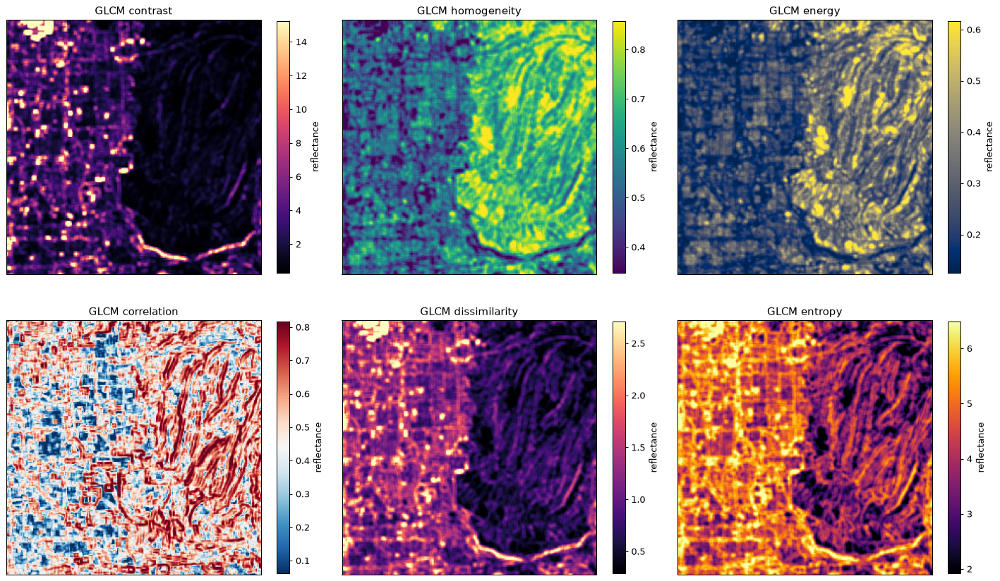

In [13]:
# GLCM of NIR: 9 x 9 window, 32 gray levels, distance 1, averaged over 4 directions.
t0 = time.time()  # start the timer
# step=2: features every second pixel, then interpolated back
glcm = tx.glcm_texture(nir, size=9, step=2, levels=32)
print(f"glcm_texture: {time.time() - t0:.1f} s ->", list(glcm.data_vars))  # run time and the features

cm = {"contrast": "magma", "homogeneity": "viridis", "energy": "cividis",  # a colour map per feature
      "correlation": "RdBu_r", "dissimilarity": "magma", "entropy": "inferno"}
fig, axes = plt.subplots(2, 3, figsize=(16, 10))  # 2 x 3 panels
for ax, f in zip(axes.ravel(), glcm.data_vars):  # one panel per feature
    rs.viz.plot_raster(glcm[f], ax=ax, cmap=cm[f], title=f"GLCM {f}")  # draw the feature
    ax.set_xticks([]); ax.set_yticks([])  # no pixel ticks
plt.tight_layout(); plt.show()  # arrange and draw

Contrast, dissimilarity and entropy are high over the city and along the Wash; homogeneity and energy
are high on the fan and the ridges. Correlation is highest along the ridges, where reflectance changes
gradually and consistently across each fold, and lowest inside city blocks where neighbouring pixels
change abruptly.


In [14]:
# GLCM features are strongly inter-related. Their correlation shows which ones are redundant.
# pixels as rows, features as columns; 30,000 random pixels
g_df = glcm.to_dataframe()[list(glcm.data_vars)].dropna().sample(30000, random_state=0)
g_df.corr().round(2)  # correlation between the six GLCM features

,contrast,homogeneity,energy,correlation,dissimilarity,entropy
contrast,1.00,-0.68,-0.53,0.02,0.91,0.67
homogeneity,-0.68,1.00,0.91,0.08,-0.91,-0.95
energy,-0.53,0.91,1.00,-0.15,-0.77,-0.95
correlation,0.02,0.08,-0.15,1.00,-0.02,0.18
dissimilarity,0.91,-0.91,-0.77,-0.02,1.00,0.89
entropy,0.67,-0.95,-0.95,0.18,0.89,1.00


Contrast and dissimilarity measure almost the same thing (r = 0.91), and homogeneity, energy and entropy
form one tight group (|r| = 0.91 to 0.95). Correlation is nearly independent of all the others
(|r| ≤ 0.18). Three features (contrast, homogeneity and correlation) cover most of the GLCM information
in this scene.


### Direction

Averaging over four angles makes GLCM rotation-invariant. Computing it for one angle at a time shows
**directional** texture. The Las Vegas street grid runs north-south and east-west, and the ridges of
Frenchman Mountain strike roughly north-north-east.


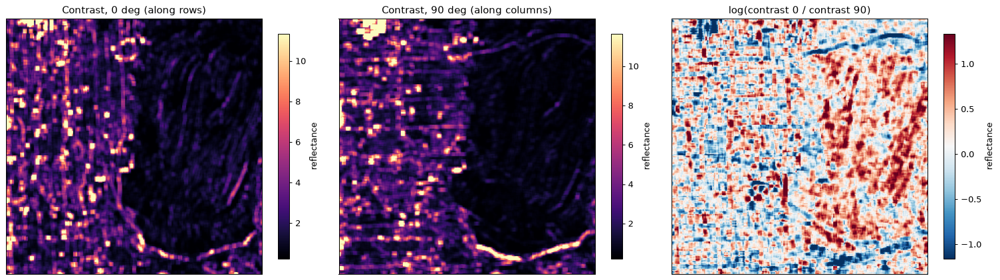

In [15]:
# Contrast measured only horizontally (0 deg) and only vertically (90 deg).
# angle 0: pairs along rows
c0 = tx.glcm_texture(nir, size=9, step=2, angles=(0.0,), props=("contrast",))["contrast"]
# angle pi/2: pairs along columns
c90 = tx.glcm_texture(nir, size=9, step=2, angles=(np.pi / 2,), props=("contrast",))["contrast"]

# Log-ratio > 0: stronger contrast along rows (features running north-south); < 0: the reverse.
ratio = np.log((c0 + 1e-3) / (c90 + 1e-3))  # 1e-3 avoids dividing by zero

fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # three panels
rs.viz.plot_raster(c0, ax=axes[0], cmap="magma", title="Contrast, 0 deg (along rows)")  # horizontal contrast
rs.viz.plot_raster(c90, ax=axes[1], cmap="magma", title="Contrast, 90 deg (along columns)")  # vertical contrast
# red: horizontal stronger; blue: vertical stronger
rs.viz.plot_raster(ratio, ax=axes[2], cmap="RdBu_r", title="log(contrast 0 / contrast 90)")
for a in axes:  # no pixel ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

The ratio is clearly positive (red) over Frenchman Mountain: its ridges strike roughly north-north-east,
so moving along a row crosses them (high contrast) while moving along a column follows them. East-west
features, such as reaches of the Wash and the road along the northern edge, are negative (blue). In the
city the sign changes block by block, following the north-south and east-west streets.


### Gray levels and window size

A 9 × 9 window holds 81 pixels, which must populate an `levels` × `levels` matrix. With many levels the
matrix becomes sparse and the features unstable.


In [16]:
# Effect of the number of gray levels and the window size on GLCM contrast and homogeneity.
rows = []  # one row per combination
for levels in [8, 16, 32, 64]:  # quantisation: 8 to 64 gray levels
    for size in [5, 9, 15]:  # window: 5, 9 and 15 pixels
        t0 = time.time()  # time each combination
        # step=4 for speed
        g = tx.glcm_texture(nir, size=size, step=4, levels=levels, props=("contrast", "homogeneity"))
        c, h = g["contrast"].values, g["homogeneity"].values  # values as NumPy arrays
        rows.append({"levels": levels, "window": size,  # median, interquartile range and run time
                     "contrast median": np.nanmedian(c),
                     "contrast IQR": np.subtract(*np.nanpercentile(c, [75, 25])),  # 75th minus 25th percentile
                     "homogeneity median": np.nanmedian(h),
                     "seconds": round(time.time() - t0, 1)})
pd.DataFrame(rows).round(3)  # the comparison table

,levels,window,contrast median,contrast IQR,homogeneity median,seconds
0,8,5,0.269,0.284,0.866,0.9
1,8,9,0.269,0.229,0.868,0.9
2,8,15,0.269,0.215,0.870,0.9
3,16,5,0.497,0.584,0.773,1.1
4,16,9,0.538,0.631,0.775,1.0
5,16,15,0.579,0.687,0.773,1.0
6,32,5,1.562,2.500,0.602,1.6
7,32,9,1.752,2.692,0.600,1.6
8,32,15,1.993,2.890,0.597,1.6
9,64,5,5.909,10.366,0.402,3.8


Contrast depends strongly on the number of gray levels: its median grows from about 0.27 at 8 levels to
6 to 8 at 64 levels, because squared gray-level differences grow with the quantization range.
Homogeneity falls from about 0.87 to 0.40. **GLCM values are comparable only between images processed
with the same `levels`, window and quantization range.** The window size changes the medians much less
than `levels` does. Run time grows with `levels`; 32 is a good default.


### GLCM on several bands at once

When the input has a leading `band` dimension, the GLCM is computed for every band in one call.


('band', 'y', 'x') (4, 512, 512)


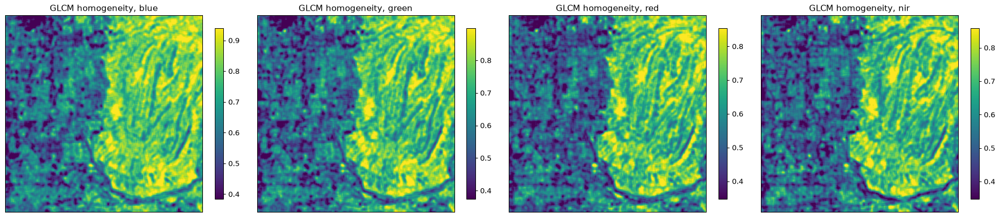

Correlation of GLCM homogeneity between bands:
       blue  green   red   nir
blue   1.00   0.97  0.94  0.89
green  0.97   1.00  0.96  0.91
red    0.94   0.96  1.00  0.95
nir    0.89   0.91  0.95  1.00


In [17]:
stack = sub[BANDS].to_array("band")  # the four bands as one DataArray with a 'band' dimension
# GLCM homogeneity of every band in one call
g_bands = tx.glcm_texture(stack, size=9, step=2, props=("homogeneity",))
print(g_bands["homogeneity"].dims, g_bands["homogeneity"].shape)  # the result keeps the band dimension

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))  # one panel per band
for ax, b in zip(axes, BANDS):  # loop over the bands
    rs.viz.plot_raster(g_bands["homogeneity"].sel(band=b), ax=ax, cmap="viridis",  # homogeneity of this band
                       title=f"GLCM homogeneity, {b}")
    ax.set_xticks([]); ax.set_yticks([])  # no pixel ticks
plt.tight_layout(); plt.show()  # arrange and draw

# one column per band, one row per pixel
h_df = pd.DataFrame({b: g_bands["homogeneity"].sel(band=b).values.ravel() for b in BANDS}).dropna()
print("Correlation of GLCM homogeneity between bands:")  # how similar the four homogeneity layers are
print(h_df.corr().round(2))  # correlation table

The four homogeneity maps look almost the same (r = 0.89 to 0.97 between bands). Texture from the most
informative band is usually enough; computing it on every band mostly adds redundant layers.


## Gray-Level Run-Length Matrix (GLRLM)

### A worked example

The same 4 × 4 toy image, read row by row: each run is a maximal sequence of equal gray levels.


In [18]:
def runs_of(line):  # split a 1-D sequence into runs of equal values
    """Gray level and length of every run in a 1-D sequence."""
    out, start = [], 0  # start = first index of the current run
    for k in range(1, len(line) + 1):  # walk along the line (one step past the end)
        if k == len(line) or line[k] != line[start]:  # the run ends at the line end or where the value changes
            # store (gray level, run length) and start a new run
            out.append((int(line[start]), k - start)); start = k
    return out  # list of runs

all_runs = [r for row in toy for r in runs_of(row)]  # horizontal runs of every row of the toy image
# the run-length matrix
R = np.zeros((4, 4), int)                    # R[gray level, run length - 1]
for g, length in all_runs:  # count each run
    R[g, length - 1] += 1  # column = run length minus one
print("Horizontal runs (gray level, length):", all_runs)  # the runs
# the matrix as a labelled table
print(pd.DataFrame(R, index=[f"level {g}" for g in range(4)], columns=[f"length {r}" for r in range(1, 5)]))

lengths = np.array([length for _, length in all_runs], float)  # length of every run
# short-run emphasis, long-run emphasis and run percentage
print(f"\nSRE = {np.mean(1 / lengths**2):.3f}, LRE = {np.mean(lengths**2):.3f}, RP = {len(lengths) / toy.size:.3f}")

Horizontal runs (gray level, length): [(0, 2), (1, 2), (0, 2), (1, 2), (0, 1), (2, 3), (2, 2), (3, 2)]
         length 1  length 2  length 3  length 4
level 0         1         2         0         0
level 1         0         2         0         0
level 2         0         1         1         0
level 3         0         1         0         0

SRE = 0.326, LRE = 4.250, RP = 0.500


The 16 pixels form 8 horizontal runs, so RP = 0.5. Most runs have length 2 and one has length 3, giving
LRE = 4.25. A finer texture (more, shorter runs) would raise SRE and RP; a striped texture with long
uniform rows would raise LRE.


`tx.glrlm_texture(img, size, step, levels, directions, features)` computes SRE, LRE and RP from the
horizontal and/or vertical runs of each quantized window. Run statistics need enough pixels per window,
so GLRLM uses a larger default window (16 × 16) and fewer gray levels (16) than GLCM.


glrlm_texture: 4.4 s -> ['SRE', 'LRE', 'RP']


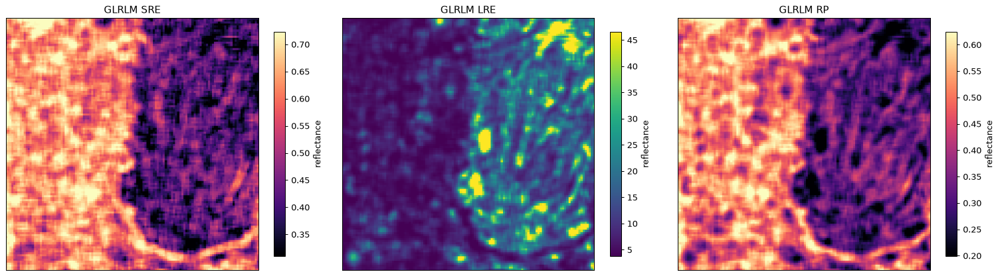

In [19]:
t0 = time.time()  # start the timer
glrlm = tx.glrlm_texture(nir, size=16, step=4, levels=16)  # 16 x 16 windows, 16 gray levels, every fourth pixel
# run time and the features (SRE, LRE, RP)
print(f"glrlm_texture: {time.time() - t0:.1f} s ->", list(glrlm.data_vars))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # three panels
# one panel and colour map per feature
for ax, f, c in zip(axes, glrlm.data_vars, ["magma", "viridis", "magma"]):
    rs.viz.plot_raster(glrlm[f], ax=ax, cmap=c, title=f"GLRLM {f}")  # draw the feature
    ax.set_xticks([]); ax.set_yticks([])  # no pixel ticks
plt.tight_layout(); plt.show()  # arrange and draw

The city has short runs (high SRE and RP), because the quantized gray level changes every one or two
pixels across the street grid. The fan and the ridges have long runs: in the sample boxes LRE is 5.6 in
the city, 28.4 on the fan and 22.7 on the ridges, and RP is 0.54 against 0.29 on both natural surfaces.


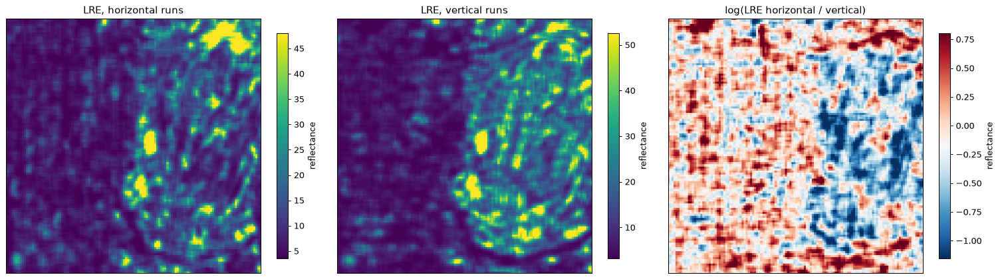

In [20]:
# Directional runs: horizontal only vs vertical only.
# long-run emphasis from horizontal runs only
rp_h = tx.glrlm_texture(nir, size=16, step=4, levels=16, directions=("horizontal",), features=("LRE",))["LRE"]
# long-run emphasis from vertical runs only
rp_v = tx.glrlm_texture(nir, size=16, step=4, levels=16, directions=("vertical",), features=("LRE",))["LRE"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))  # three panels
rs.viz.plot_raster(rp_h, ax=axes[0], cmap="viridis", title="LRE, horizontal runs")  # horizontal runs
rs.viz.plot_raster(rp_v, ax=axes[1], cmap="viridis", title="LRE, vertical runs")  # vertical runs
# red: longer horizontal runs; blue: longer vertical runs
rs.viz.plot_raster(np.log(rp_h / rp_v), ax=axes[2], cmap="RdBu_r", title="log(LRE horizontal / vertical)")
for a in axes:  # no pixel ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

On the ridges vertical runs are longer than horizontal runs (blue), because a column follows a
north-north-east striking ridge while a row cuts across it. East-west features (the southern reaches of
the Wash, the road along the northern edge, east-west streets) give longer horizontal runs (red). This
is the run-length counterpart of the directional GLCM map in the GLCM section.


## Structural texture: edge density and lacunarity

`tx.edge_density(img, size, sigma, low_threshold, high_threshold)` runs Canny on the band and returns the
share of edge pixels in each `size` × `size` window. `tx.lacunarity(img, box_sizes, size)` returns one
gliding-box lacunarity layer per box size, computed inside a moving analysis window (default
4 × the largest box).

### A toy check of lacunarity

Two binary patterns with the same 30% cover: one random, one clumped. Their means are identical, but
lacunarity separates them at every box size.


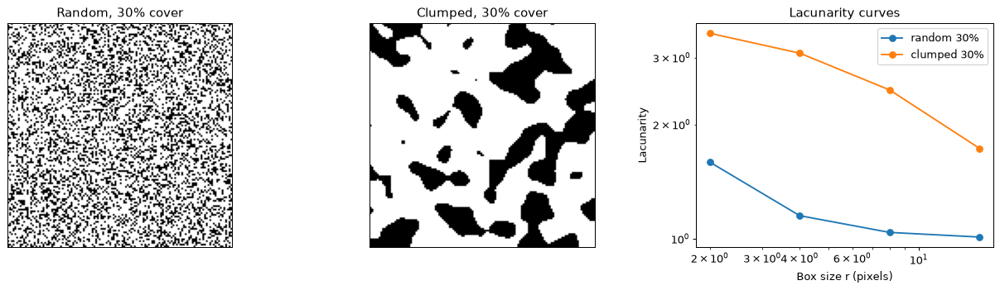

,random 30%,clumped 30%
r = 2,1.592,3.477
r = 4,1.150,3.081
r = 8,1.039,2.466
r = 16,1.010,1.730


In [21]:
from scipy.ndimage import gaussian_filter  # smoothing filter
rng = np.random.default_rng(1)  # random generator with a fixed seed
random_pat = (rng.random((128, 128)) < 0.3).astype(float)  # 30 % of pixels set at random
smooth = gaussian_filter(rng.random((128, 128)), 4)  # smoothed noise has patches
# the top 30 % of the smoothed noise: same cover, clumped
clumped = (smooth > np.quantile(smooth, 0.7)).astype(float)

boxes = (2, 4, 8, 16)  # gliding-box sizes in pixels
# mean lacunarity per box size (rows) and pattern (columns)
lac_tab = pd.DataFrame({name: {f"r = {r}": float(np.nanmean(tx.lacunarity(p, box_sizes=(r,), size=64)[f"lac_r{r}"]))
                               for r in boxes}  # one value per box size
                        # the two patterns
                        for name, p in [("random 30%", random_pat), ("clumped 30%", clumped)]})

fig, axes = plt.subplots(1, 3, figsize=(14, 4))  # two patterns and their curves
axes[0].imshow(random_pat, cmap="gray_r"); axes[0].set_title("Random, 30% cover")  # random pattern
axes[1].imshow(clumped, cmap="gray_r"); axes[1].set_title("Clumped, 30% cover")  # clumped pattern
for name in lac_tab:  # one curve per pattern
    axes[2].plot(boxes, lac_tab[name], "o-", label=name)  # lacunarity against box size
# log-log axes
axes[2].set(xscale="log", yscale="log", xlabel="Box size r (pixels)", ylabel="Lacunarity", title="Lacunarity curves")
axes[2].legend()  # legend
for a in axes[:2]:  # no ticks on the two images
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw
# show the table
lac_tab.round(3)

Both patterns cover 30% of the area, but the clumped pattern has two to three times the lacunarity at
every box size. Lacunarity of the random pattern drops to about 1 by r = 8 (uniform at that scale),
while the clumped pattern stays heterogeneous up to r = 16, the size of its clumps.


edge_density + lacunarity: 0.1 s


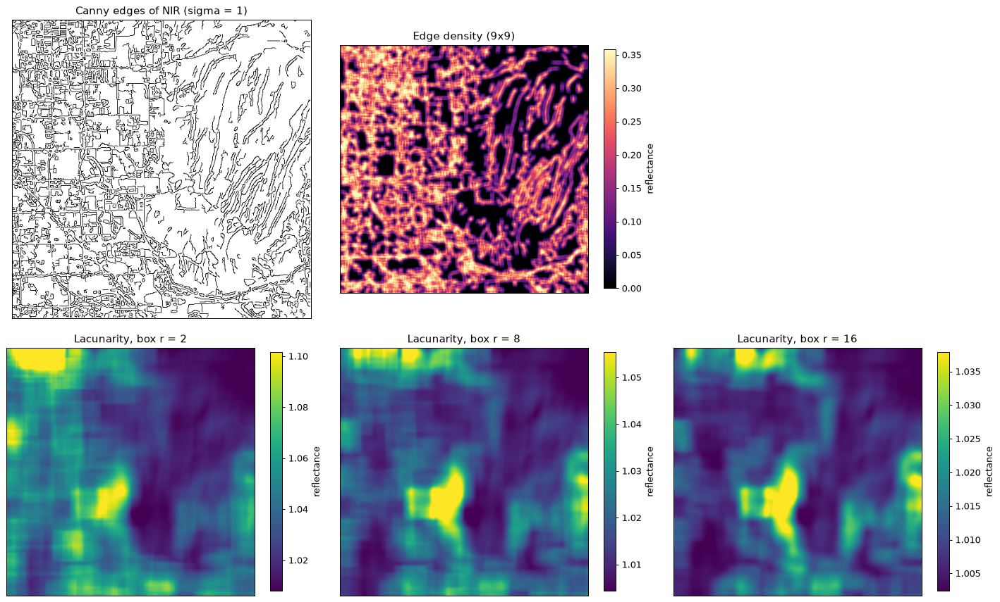

In [22]:
t0 = time.time()  # start the timer
edens = tx.edge_density(nir, size=9, sigma=1.0)  # share of Canny edge pixels in each 9 x 9 window
lac = tx.lacunarity(nir, box_sizes=(2, 4, 8, 16))  # lacunarity at four box sizes
print(f"edge_density + lacunarity: {time.time() - t0:.1f} s")  # run time

from skimage.feature import canny  # the Canny detector itself, to show the edges
# NaN replaced by the mean so Canny can run
edges = canny(np.nan_to_num(nir.values, nan=float(nir.mean())), sigma=1.0)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))  # 2 x 3 panels
# the edge pixels
axes[0, 0].imshow(edges, cmap="gray_r"); axes[0, 0].set_title("Canny edges of NIR (sigma = 1)")
rs.viz.plot_raster(edens, ax=axes[0, 1], cmap="magma", title="Edge density (9x9)")  # edge density
axes[0, 2].axis("off")  # empty panel
for ax, f in zip(axes[1], ["lac_r2", "lac_r8", "lac_r16"]):  # lacunarity at three of the box sizes
    # draw it; the title takes the box size from the layer name
    rs.viz.plot_raster(lac[f], ax=ax, cmap="viridis", title=f"Lacunarity, box r = {f.split('r')[-1]}")
for a in axes.ravel():  # no pixel ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

About a quarter of the pixels in the urban sample box are Canny edges (edge density 0.26), against 0.08
on the fan and 0.10 on the ridges. The edge map reproduces the street grid, and on the mountain it traces
individual ridge lines while the slopes between them stay edge-free.

On reflectance, lacunarity stays close to 1 (1.01 to 1.04 in the sample boxes) because reflectance never
drops to zero, so there are no true gaps. The highest values are where very bright and very dark
surfaces meet inside one analysis window: the large commercial roofs in the north-west and the dark
parks and ponds next to the bright fan. The range shrinks as the box grows, because larger boxes average
the clumps out. Lacunarity is most useful on binary or sparse layers, such as a tree or building mask.


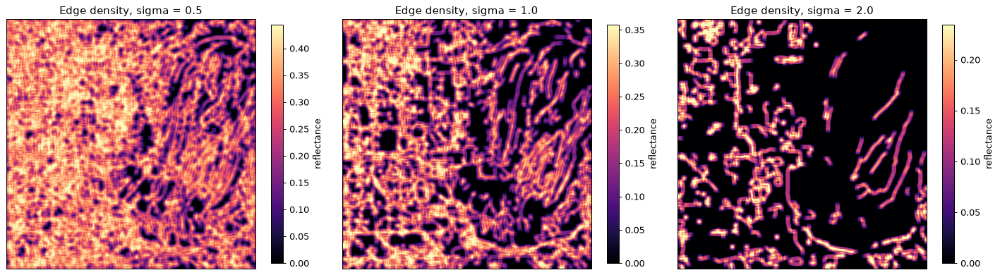

In [23]:
# Edge density depends on the Canny smoothing scale sigma.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))  # three panels
for ax, s in zip(axes, [0.5, 1.0, 2.0]):  # three smoothing scales
    # edge density at this sigma
    rs.viz.plot_raster(tx.edge_density(nir, size=9, sigma=s), ax=ax, cmap="magma", title=f"Edge density, sigma = {s}")
    ax.set_xticks([]); ax.set_yticks([])  # no pixel ticks
plt.tight_layout(); plt.show()  # arrange and draw

A small `sigma` (0.5) detects noise edges everywhere, even on the fan. With `sigma = 2` only the main
streets, the Wash and the major ridge lines remain. `sigma = 1` keeps the street grid while suppressing
most noise on the natural surfaces.


## Application: texture signatures and clustering


Three 40 × 40 pixel boxes (1.2 × 1.2 km), chosen by eye on the false-colour image, are used to compare
texture signatures:

| Box | Rows | Columns | Surface |
|---|---|---|---|
| Urban grid | 100-140 | 40-80 | Residential blocks and streets |
| Alluvial fan | 300-340 | 270-310 | Smooth bare desert soil |
| Mountain ridges | 130-170 | 400-440 | Folded sedimentary ridges of Frenchman Mountain |


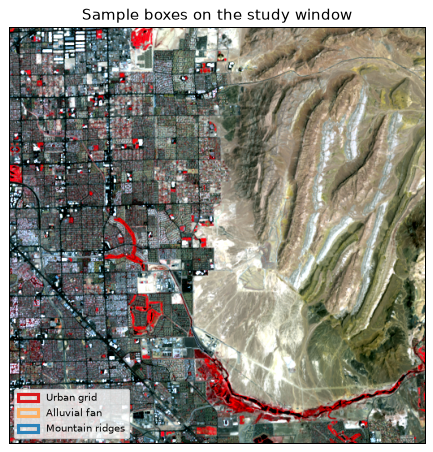

In [24]:
# three 40 x 40 pixel sample boxes (rows, columns) in the study window
BOXES = {"Urban grid": (slice(100, 140), slice(40, 80)),
         "Alluvial fan": (slice(300, 340), slice(270, 310)),  # gravel slopes east of the city
         "Mountain ridges": (slice(130, 170), slice(400, 440))}  # rugged terrain
# one colour per box
COLORS = {"Urban grid": "#d7191c", "Alluvial fan": "#fdae61", "Mountain ridges": "#2b83ba"}

fig, ax = plt.subplots(figsize=(6, 6))  # one panel
# colour infrared background
rs.viz.plot_rgb(sub, "false_color", ax=ax, title="Sample boxes on the study window")
for name, (ys, xs) in BOXES.items():  # draw each box
    # x = column start, y = row start, then width and height
    ax.add_patch(Rectangle((xs.start, ys.start), xs.stop - xs.start, ys.stop - ys.start,
                           # outline only, labelled for the legend
                           fill=False, ec=COLORS[name], lw=2.5, label=name))
ax.legend(loc="lower left", fontsize=8); ax.set_xticks([]); ax.set_yticks([])  # legend, no ticks
plt.show()  # draw

In [25]:
from sklearn.cluster import KMeans  # k-means clustering
from sklearn.preprocessing import StandardScaler  # standardise features to mean 0, std 1
from scipy.ndimage import generic_filter  # moving-window filter for the speckle measure

def box_means(ds):  # average feature values per sample box
    """Mean of every variable of `ds` inside each sample box."""
    # rows = features, columns = boxes
    return pd.DataFrame({name: {v: float(ds[v].isel(y=ys, x=xs).mean()) for v in ds.data_vars}
                         for name, (ys, xs) in BOXES.items()})

def plot_signatures(sig, title):  # compare the boxes feature by feature
    """Bar chart of box means, min-max scaled per feature across the three boxes."""
    # scale each feature to 0-1 across the three boxes
    norm = sig.sub(sig.min(axis=1), axis=0).div(sig.max(axis=1) - sig.min(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(max(7, 0.75 * len(norm)), 4.5))  # width grows with the number of features
    x = np.arange(len(norm))  # one group of bars per feature
    for k, name in enumerate(norm.columns):  # one bar per box, shifted sideways
        ax.bar(x + (k - 1) * 0.27, norm[name], width=0.27, color=COLORS[name], label=name)  # draw the bars
    ax.set_xticks(x, norm.index, rotation=45, ha="right")  # feature names, rotated
    ax.set(ylabel="Relative value (0 = lowest box, 1 = highest)", title=title)  # labels
    ax.legend(); plt.tight_layout(); plt.show()  # legend and draw

def kmeans_map(ds, k=5, n_fit=40000, seed=0):  # unsupervised map from a set of layers
    """Standardize the layers, fit k-means on a random pixel sample and label every pixel."""
    df = ds.to_dataframe(dim_order=["y", "x"])[list(ds.data_vars)]  # pixels as rows, layers as columns
    ok = df.notna().all(axis=1).values  # pixels without missing values
    X = StandardScaler().fit_transform(df[ok].values)  # standardise so every layer weighs the same
    rng = np.random.default_rng(seed)  # random sample generator
    # fit on at most 40,000 random pixels (faster)
    km = KMeans(k, n_init=10, random_state=seed).fit(X[rng.choice(len(X), min(n_fit, len(X)), replace=False)])
    lab = np.full(ok.size, np.nan); lab[ok] = km.predict(X)  # label all valid pixels; others stay NaN
    # labels back on the image grid
    return xr.DataArray(lab.reshape(ds.sizes["y"], ds.sizes["x"]), coords={"y": ds.y, "x": ds.x}, dims=("y", "x"))

def speckle(lab):  # how noisy a cluster map is
    """Share of pixels whose label differs from the majority label of their 3 x 3 neighbourhood."""
    a = np.nan_to_num(lab.values, nan=-1).astype(int)  # NaN -> -1 so the labels are integers
    # majority label in each 3 x 3 window
    mode = generic_filter(a, lambda v: np.bincount(v.astype(int) + 1).argmax() - 1, size=3)
    return float((a != mode).mean())  # share of pixels that differ from their neighbourhood majority

def box_purity(lab):  # how uniform each box is in a cluster map
    """Share of each box's pixels that fall in the box's most common cluster."""
    out = {}  # one value per box
    for name, (ys, xs) in BOXES.items():  # loop over the boxes
        v = lab.isel(y=ys, x=xs).values.ravel()  # labels inside the box
        v = v[np.isfinite(v)].astype(int)  # drop missing labels
        out[name] = np.bincount(v).max() / v.size  # share of the most common label
    return out  # dictionary box -> purity

# Spectral layers used as the baseline in every notebook: the four bands and NDVI.
# normalised difference vegetation index
ndvi = ((sub["nir"] - sub["red"]) / (sub["nir"] + sub["red"])).rename("NDVI")
spectral = xr.Dataset({**{b: sub[b] for b in BANDS}, "NDVI": ndvi})  # four bands plus NDVI

In [26]:
stat_feats = xr.Dataset({  # the texture layers of this notebook in one Dataset
    # first-order statistics
    "NIR std": fos["std"], "NIR skewness": fos["skewness"], "NIR entropy": fos["entropy"],
    "GLCM contrast": glcm["contrast"], "GLCM homogeneity": glcm["homogeneity"],  # GLCM features
    "GLCM correlation": glcm["correlation"], "GLCM entropy": glcm["entropy"],  # more GLCM features
    "GLRLM SRE": glrlm["SRE"], "GLRLM LRE": glrlm["LRE"], "GLRLM RP": glrlm["RP"],  # run-length features
    "Edge density": edens, "Lacunarity r4": lac["lac_r4"],  # structural features
})
sig = box_means(stat_feats)  # mean of every feature in every sample box
# show the table
sig.round(4)

,Urban grid,Alluvial fan,Mountain ridges
NIR std,0.0653,0.0266,0.0310
NIR skewness,0.1643,-0.0522,0.0018
NIR entropy,2.7501,1.6567,1.7080
GLCM contrast,4.6090,0.8619,0.8265
GLCM homogeneity,0.4766,0.7248,0.7429
GLCM correlation,0.5083,0.5043,0.5883
GLCM entropy,5.3309,3.2812,3.2565
GLRLM SRE,0.6383,0.3991,0.3962
GLRLM LRE,5.6354,28.3656,22.6576
GLRLM RP,0.5356,0.2934,0.2920


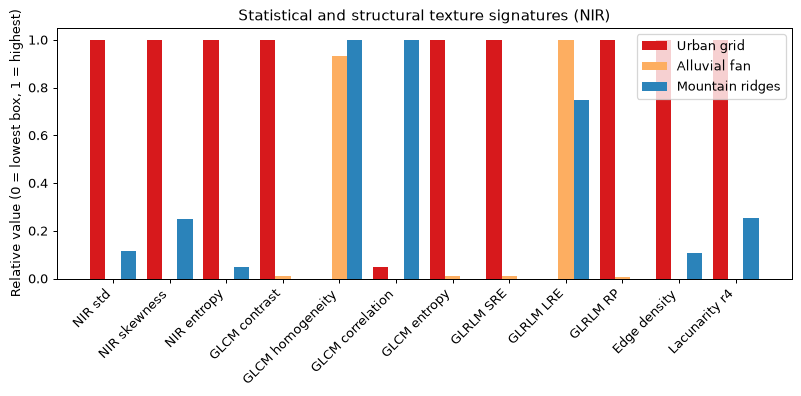

In [27]:
plot_signatures(sig, "Statistical and structural texture signatures (NIR)")  # bar chart of the box signatures

The urban grid has the highest value on every roughness feature (std, entropy, GLCM contrast and entropy,
SRE, RP, edge density), often 3 to 5 times the natural surfaces. The fan and the ridges are similar on
most features: at 30 m both are smooth. They differ in GLCM correlation (0.59 on the ridges, 0.50 on the
fan) and in run length (LRE 28 on the fan, 23 on the ridges). No single feature separates all three
surfaces, but a combination does.


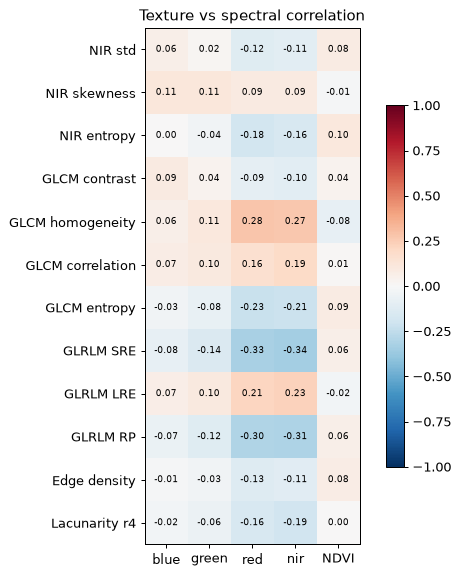

In [28]:
# Correlation of each texture feature with the spectral layers.
# spectral and texture layers together; pixels as rows
df_all = xr.merge([spectral, stat_feats], compat="override").to_dataframe()[
    list(spectral.data_vars) + list(stat_feats.data_vars)].dropna()  # keep these columns, drop pixels with gaps
# correlation of each texture feature (rows) with each spectral layer (columns)
cross = df_all.corr().loc[list(stat_feats.data_vars), list(spectral.data_vars)]
fig, ax = plt.subplots(figsize=(6, 6.5))  # one panel
im = ax.imshow(cross, cmap="RdBu_r", vmin=-1, vmax=1)  # the correlation matrix as an image
# label rows and columns
ax.set_xticks(range(cross.shape[1]), cross.columns); ax.set_yticks(range(cross.shape[0]), cross.index)
for i in range(cross.shape[0]):  # write each value in its cell
    for j in range(cross.shape[1]):  # columns
        ax.text(j, i, f"{cross.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)  # two decimals
plt.colorbar(im, shrink=0.7); ax.set_title("Texture vs spectral correlation")  # colour bar and title
plt.tight_layout(); plt.show()  # arrange and draw

Every statistical texture feature is only weakly correlated with the spectral bands (|r| ≤ 0.34) and
almost uncorrelated with NDVI. **Texture carries information that the spectral layers do not.**


### Does this family add information? A clustering test

Texture is useful only if it carries information that the spectral bands do not. We run k-means with
5 clusters on (a) the four bands and NDVI only and (b) the same spectral layers plus this notebook's
texture features, all standardized. Two numbers summarize the maps:

- **Speckle**: the share of pixels whose cluster differs from the majority of their 3 × 3
  neighbourhood (lower = more spatially coherent).
- **Purity**: the share of pixels in each sample box that fall in that box's most common cluster
  (higher = the surface is mapped as one unit).


In [29]:
def compare_clusterings(texture_ds, label):  # clustering with and without the texture layers
    """k-means on spectral layers only vs spectral + texture layers; maps, speckle and box purity."""
    k_spec = kmeans_map(spectral)  # five spectral layers
    k_both = kmeans_map(xr.merge([spectral, texture_ds], compat="override"))  # spectral plus texture layers
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))  # three panels
    rs.viz.plot_rgb(sub, "false_color", ax=axes[0], title="Colour infrared")  # reference image
    for ax, lab, t in zip(axes[1:], [k_spec, k_both],  # the two cluster maps with their titles
                          ["k-means, spectral only (5 layers)",
                           f"k-means, spectral + {label} ({5 + len(texture_ds.data_vars)} layers)"]):
        ax.imshow(lab, cmap="Set2", interpolation="nearest")  # one colour per cluster
        ax.set_title(f"{t}\nspeckle = {speckle(lab):.1%}")  # title with the speckle share
    for a in axes:  # no pixel ticks
        a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()  # arrange and draw
    return pd.DataFrame({"spectral only": box_purity(k_spec),  # box purity of both maps, as percentages
                         # format each value as a percentage
                         f"spectral + {label}": box_purity(k_both)}).map(lambda v: f"{v:.0%}")

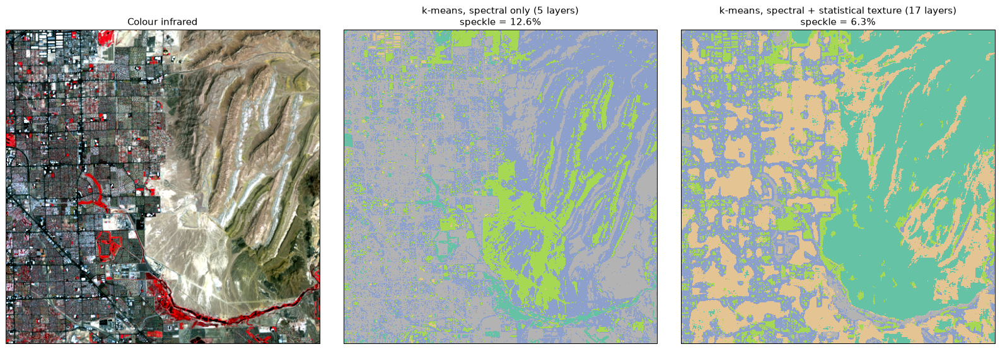

,spectral only,spectral + statistical texture
Urban grid,53%,70%
Alluvial fan,58%,91%
Mountain ridges,66%,95%


In [30]:
# Log-transform the heavy-tailed features before clustering.
stat_km = stat_feats.copy()  # a copy used only for clustering
for f in ["GLCM contrast", "GLRLM LRE"]:  # these two features have long right tails
    stat_km[f] = np.log10(stat_feats[f] + 1e-6)  # log scale makes them less dominated by a few large values
compare_clusterings(stat_km, "statistical texture")  # maps, speckle and box purity

With spectral layers only, k-means splits the scene by brightness: the fan and the ridges are cut into
interleaved light and dark clusters, the city is a salt-and-pepper mix, and 12.6% of the pixels disagree
with their neighbourhood. Adding statistical texture halves the speckle (6.3%) and raises purity in
every box: from 53% to 70% in the city, 58% to 91% on the fan and 66% to 95% on the ridges. The clusters
now follow land-surface units: one smooth natural desert, two kinds of city blocks, and the Wash.

The cost: window-based texture blurs boundaries by about half a window (135 m for 9 × 9), and the fan and
ridges, which are spectrally distinct, fall into one cluster. Texture works best together with spectral
layers in a supervised classifier that can weight each layer.


### Saving texture layers

Each texture result keeps the coordinates and CRS of the input, so it can be written directly as a
GeoTIFF and stacked with other predictors.


In [31]:
OUT = Path("outputs") / "texture"  # output folder for texture rasters
OUT.mkdir(parents=True, exist_ok=True)  # create it if needed
# Dataset -> one multi-band GeoTIFF (one band per feature)
stat_feats.to_array("feature").astype("float32").rio.write_crs(ls.rio.crs).rio.to_raster(OUT / "nir_statistical_texture.tif")
with rasterio.open(OUT / "nir_statistical_texture.tif") as src:  # read the file back to check it
    # number of bands, size and CRS
    print(f"nir_statistical_texture.tif: {src.count} bands, {src.width} x {src.height}, {src.crs}")

nir_statistical_texture.tif: 12 bands, 512 x 512, EPSG:32611


## Summary and exercises

**Key points**

- First-order statistics are fast but blind to spatial arrangement; two windows with the same histogram
  get the same values (see *Why texture? Same histogram, different arrangement*).
- GLCM measures how gray levels co-occur at a given offset. Contrast/dissimilarity, the
  homogeneity/energy/entropy group and correlation cover most of its information.
- GLCM values depend strongly on `levels` and the quantization range, so compare only images processed
  with identical settings.
- Directional GLCM and GLRLM reveal oriented structures: street grids, ridges, crop rows.
- Edge density and lacunarity describe the density and gap structure of primitives; lacunarity is most
  informative on sparse or binary layers.
- Texture from different bands of the same scene is highly redundant; one band (here NIR) is usually
  enough.

**`geolattice.rsense` functions used:** `rs.read`, `rs.optical.scale`, `rs.viz.plot_rgb`, `rs.viz.plot_raster`,
`tx.first_order_stats`, `tx.glcm_texture`, `tx.glrlm_texture`, `tx.edge_density`, `tx.lacunarity`.

**Exercises**

1. Compute GLCM texture on NDVI instead of NIR. Which surfaces change their texture signature?
2. Compute contrast for each of the four angles separately and map the direction of maximum contrast.
   Does it follow the street grid and the strike of the ridges?
3. Run `tx.glcm_texture` with `distance=2` and `distance=4`. How does contrast change over the city?
4. Threshold NDVI > 0.3 to make a vegetation mask and compute its lacunarity. At which box size does
   the Las Vegas Wash differ most from the city parks?
5. Repeat the clustering test with only three features: one first-order, one GLCM and one structural.

**References**

- Canny, J. (1986). A computational approach to edge detection. *IEEE TPAMI*, 8(6), 679-698.
- Galloway, M.M. (1975). Texture analysis using gray level run lengths. *Computer Graphics and Image
  Processing*, 4(2), 172-179.
- Haralick, R.M., Shanmugam, K. and Dinstein, I. (1973). Textural features for image classification.
  *IEEE Transactions on Systems, Man, and Cybernetics*, SMC-3(6), 610-621.
- Plotnick, R.E., Gardner, R.H., Hargrove, W.W., Prestegaard, K. and Perlmutter, M. (1996). Lacunarity
  analysis: a general technique for the analysis of spatial patterns. *Physical Review E*, 53(5),
  5461-5468.

**Next:** [Transform-based texture](09_07_02_texture_analysis_of_landsat_imagery_transform_based_spectral_methods.ipynb).
